In [2]:
!pip install MetaTrader5 pandas numpy scikit-learn matplotlib seaborn
!pip install ta 
!pip install python-dotenv 

In [ ]:
import MetaTrader5 as mt5
import pandas as pd

server = "MetaQuotes-Demo"
login = 108778708
password = "DtI!6xCy"

if not mt5.initialize(login=login, password=password, server=server):
        print("Connexion echoué")

In [4]:
account_info = mt5.account_info()
print(f"Compte: {account_info.name}")
print(f"Solde: {account_info.balance}")
print(f"Devise: {account_info.currency}")

Compte: Kennedy Ndjibu
Solde: 100000.0
Devise: USD


In [5]:
from datetime import datetime

mt5.initialize()

rates = mt5.copy_rates_range(
    "EURUSD",
    mt5.TIMEFRAME_D1,
    datetime(2015,1,1),
    datetime(2025,12,31)
)

df = pd.DataFrame(rates)

mt5.shutdown()

True

In [6]:
df

,time,open,high,low,close,tick_volume,spread,real_volume
0,1420156800,1.20538,1.20690,1.19997,1.20014,53082,9,0
1,1420416000,1.19454,1.19757,1.18642,1.19317,95141,10,0
2,1420502400,1.19318,1.19682,1.18836,1.18887,91697,10,0
3,1420588800,1.18889,1.18956,1.18014,1.18386,98091,9,0
4,1420675200,1.18386,1.18467,1.17536,1.17899,82605,9,0
...,...,...,...,...,...,...,...,...
2850,1766448000,1.17600,1.18019,1.17552,1.17942,51711,0,0
2851,1766534400,1.17941,1.18077,1.17726,1.17764,55551,0,0
2852,1766707200,1.17769,1.17967,1.17615,1.17712,69962,0,0
2853,1766966400,1.17631,1.17890,1.17494,1.17721,69209,0,0


In [7]:
df['time'] = pd.to_datetime(df['time'], unit='s')

In [8]:
df.head(15)

,time,open,high,low,close,tick_volume,spread,real_volume
0,2015-01-02,1.20538,1.20690,1.19997,1.20014,53082,9,0
1,2015-01-05,1.19454,1.19757,1.18642,1.19317,95141,10,0
2,2015-01-06,1.19318,1.19682,1.18836,1.18887,91697,10,0
3,2015-01-07,1.18889,1.18956,1.18014,1.18386,98091,9,0
4,2015-01-08,1.18386,1.18467,1.17536,1.17899,82605,9,0
5,2015-01-09,1.17901,1.18450,1.17623,1.18402,91031,10,0
6,2015-01-12,1.18481,1.18702,1.17856,1.18325,80991,9,0
7,2015-01-13,1.18324,1.18589,1.17529,1.17718,93072,9,0
8,2015-01-14,1.17712,1.18451,1.17267,1.17881,101182,9,0
9,2015-01-15,1.17882,1.17921,1.15673,1.16298,123477,9,0


In [9]:
df = df.drop_duplicates()

In [10]:
df = df.dropna()

In [11]:
df = df.sort_values('time')

In [12]:
df.head(15)

,time,open,high,low,close,tick_volume,spread,real_volume
0,2015-01-02,1.20538,1.20690,1.19997,1.20014,53082,9,0
1,2015-01-05,1.19454,1.19757,1.18642,1.19317,95141,10,0
2,2015-01-06,1.19318,1.19682,1.18836,1.18887,91697,10,0
3,2015-01-07,1.18889,1.18956,1.18014,1.18386,98091,9,0
4,2015-01-08,1.18386,1.18467,1.17536,1.17899,82605,9,0
5,2015-01-09,1.17901,1.18450,1.17623,1.18402,91031,10,0
6,2015-01-12,1.18481,1.18702,1.17856,1.18325,80991,9,0
7,2015-01-13,1.18324,1.18589,1.17529,1.17718,93072,9,0
8,2015-01-14,1.17712,1.18451,1.17267,1.17881,101182,9,0
9,2015-01-15,1.17882,1.17921,1.15673,1.16298,123477,9,0


In [13]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2855 entries, 0 to 2854
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype        
---  ------       --------------  -----        
 0   time         2855 non-null   datetime64[s]
 1   open         2855 non-null   float64      
 2   high         2855 non-null   float64      
 3   low          2855 non-null   float64      
 4   close        2855 non-null   float64      
 5   tick_volume  2855 non-null   uint64       
 6   spread       2855 non-null   int32        
 7   real_volume  2855 non-null   uint64       
dtypes: datetime64[s](1), float64(4), int32(1), uint64(2)
memory usage: 167.4 KB


In [14]:
df.describe()

,time,open,high,low,close,tick_volume,spread,real_volume
count,2855,2855.000000,2855.000000,2855.000000,2855.000000,2855.000000,2855.000000,2.855000e+03
mean,2020-07-02 03:52:31,1.119599,1.123956,1.115716,1.119710,86052.840630,1.639930,2.876041e+10
min,2015-01-02 00:00:00,0.959230,0.967110,0.953570,0.959240,18.000000,0.000000,0.000000e+00
25%,2017-09-30 12:00:00,1.084480,1.088635,1.080545,1.084485,52644.500000,0.000000,0.000000e+00
50%,2020-07-03 00:00:00,1.116870,1.121370,1.113050,1.117090,75108.000000,0.000000,0.000000e+00
75%,2023-04-01 12:00:00,1.159975,1.163970,1.156650,1.160230,113949.500000,2.000000,0.000000e+00
max,2025-12-30 00:00:00,1.250730,1.255540,1.244800,1.250780,321617.000000,112.000000,4.299390e+11
std,NaN,0.052052,0.051742,0.052262,0.052018,43835.043984,3.298821,6.860436e+10


In [16]:
df["SMA5"] = df["close"].rolling(5).mean()

In [17]:
df["SMA5"].head(10)

0         NaN
1         NaN
2         NaN
3         NaN
4    1.189006
5    1.185782
6    1.183798
7    1.181460
8    1.180450
9    1.177248
Name: SMA5, dtype: float64

In [18]:
df["Target"] = df["close"].shift(-1)

In [19]:
df.head()

,time,open,high,low,close,tick_volume,spread,real_volume,SMA5,Target
0,2015-01-02,1.20538,1.20690,1.19997,1.20014,53082,9,0,NaN,1.19317
1,2015-01-05,1.19454,1.19757,1.18642,1.19317,95141,10,0,NaN,1.18887
2,2015-01-06,1.19318,1.19682,1.18836,1.18887,91697,10,0,NaN,1.18386
3,2015-01-07,1.18889,1.18956,1.18014,1.18386,98091,9,0,NaN,1.17899
4,2015-01-08,1.18386,1.18467,1.17536,1.17899,82605,9,0,1.189006,1.18402


In [20]:
df = df.dropna()

In [21]:
df.head()

,time,open,high,low,close,tick_volume,spread,real_volume,SMA5,Target
4,2015-01-08,1.18386,1.18467,1.17536,1.17899,82605,9,0,1.189006,1.18402
5,2015-01-09,1.17901,1.18450,1.17623,1.18402,91031,10,0,1.185782,1.18325
6,2015-01-12,1.18481,1.18702,1.17856,1.18325,80991,9,0,1.183798,1.17718
7,2015-01-13,1.18324,1.18589,1.17529,1.17718,93072,9,0,1.181460,1.17881
8,2015-01-14,1.17712,1.18451,1.17267,1.17881,101182,9,0,1.180450,1.16298


In [22]:
train = df[:int(len(df)*0.8)]

test = df[int(len(df)*0.8):]

In [23]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

X_train = train[["SMA5"]]

y_train = train["Target"]

model.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[0.99]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['SMA5']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,0.008224
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


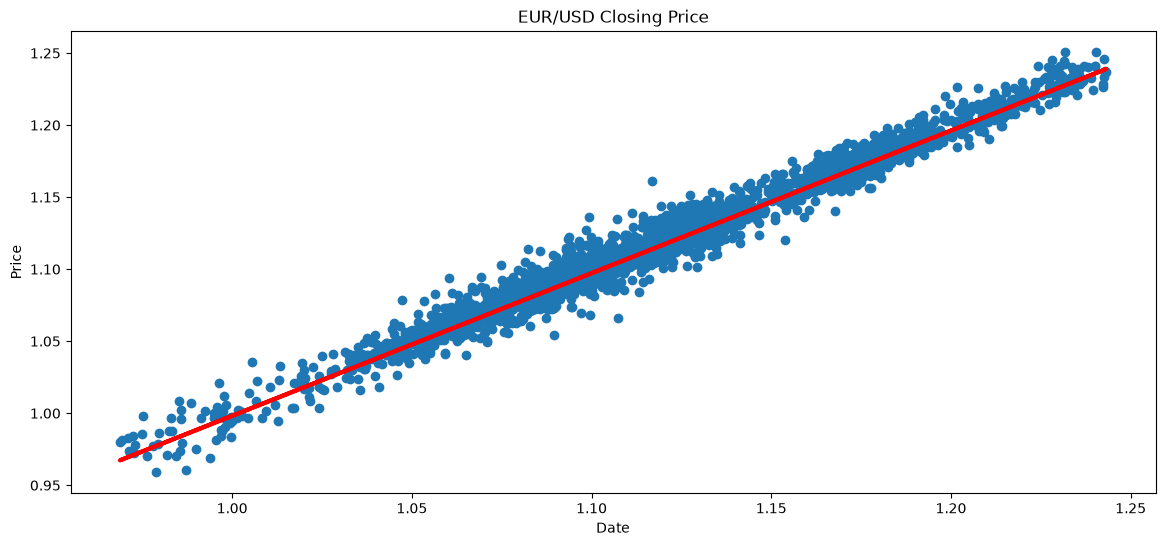

In [24]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14,6))

plt.scatter(df["SMA5"], df["Target"])
plt.plot(df["SMA5"], 0.99*df["SMA5"] + 0.008224, color='red', linewidth=3)
plt.title("EUR/USD Closing Price")
plt.xlabel("Date")
plt.ylabel("Price")

plt.show()